## Load Sentinel Packages

In [1]:
#Import libraries
import geopandas as gpd
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import odc.stac
import pystac_client
from odc.stac import load
from pystac.client import Client
import xarray as xr
from scipy import ndimage as ndi
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

## Define the study AOI

In [2]:
#Yalelevu AOI imported from asset

aoi = gpd.read_file("/home/jovyan/sentinel-1--sar--analysis/New_Soil_moisture_analysis/Namosau.geojson")
aoi = aoi.to_crs("EPSG:4326")
min_lon, min_lat, max_lon, max_lat = aoi.total_bounds

bbox = [min_lon, min_lat, max_lon, max_lat]

In [3]:
#Display Map
aoi.explore()

## Load Sentinel 1 Data

### Connect to the STAC Catalog and Define Analysis Period
 
This step establishes a connection to the Element 84 STAC (SpatioTemporal Asset Catalog) endpoint, which provides access to a range of Earth observation datasets. 
The analysis period was defined from 1 July 2024 to 30 June 2025 to retrieve imagery acquired within the study timeframe.

1. Define the timeframe

In [4]:
catalog = "https://earth-search.aws.element84.com/v1"
client = Client.open(catalog)
datetime = "2024-01-01/2024-12-30"

### Search and Retrieve Sentinel-1 SAR Imagery
This step queries the STAC catalog to retrieve Sentinel-1 Ground Range Detected (GRD) imagery covering the study area within the specified date range. 
The search is constrained to Interferometric Wide Swath (IW) acquisition mode, ascending satellite passes, and restituted orbit (RESORB) products to ensure consistency in data acquisition and processing.

2. Load the sentinel 1 collection

In [5]:
items = client.search(
    collections=["sentinel-1-grd"],
    bbox=bbox,
    datetime=datetime,
    query={
        "sar:instrument_mode": {"eq": "IW"},
        "sat:orbit_state": {"eq": "ascending"},
        "s1:orbit_source": {"eq": "RESORB"}
    }
).item_collection()

In [6]:
items

3. Loading the VV polarization

In [7]:
ds = odc.stac.load(
items,
bands=["vv", "vh"],
bbox=bbox,
chunks={}
)

In [8]:
print(ds)

<xarray.Dataset> Size: 26MB
Dimensions:      (latitude: 365, longitude: 588, time: 30)
Coordinates:
  * latitude     (latitude) float64 3kB -17.52 -17.52 -17.52 ... -17.56 -17.56
  * longitude    (longitude) float64 5kB 177.6 177.6 177.6 ... 177.7 177.7 177.7
    spatial_ref  int32 4B 4326
  * time         (time) datetime64[ns] 240B 2024-01-08T06:40:46.659976 ... 20...
Data variables:
    vv           (time, latitude, longitude) uint16 13MB dask.array<chunksize=(1, 365, 588), meta=np.ndarray>
    vh           (time, latitude, longitude) uint16 13MB dask.array<chunksize=(1, 365, 588), meta=np.ndarray>


In [9]:
# Extract VV backscatter
# Soil moisture studies
# commonly use VV polarization
# ---------------------------
vv = ds["vv"]

4. CONVERT TO dB

In [10]:
# Sentinel-1 backscatter is often analysed in dB.
# Avoid taking log of zero values.
# -----------------------------------------------------------------------------
vv_db = 10 * np.log10(vv.where(vv > 0))

In [11]:
# vv_db: your DataArray (the one you plotted earlier)
vv_mean = vv_db.mean(dim='time', skipna=True)

print("Original vv_mean stats:", float(vv_mean.min()), float(vv_mean.max()), float(vv_mean.mean()))

/srv/conda/envs/notebook/lib/python3.11/site-packages/rasterio/warp.py:387: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dest = _reproject(


Original vv_mean stats: 16.445064544677734 37.24750900268555 22.607383728027344


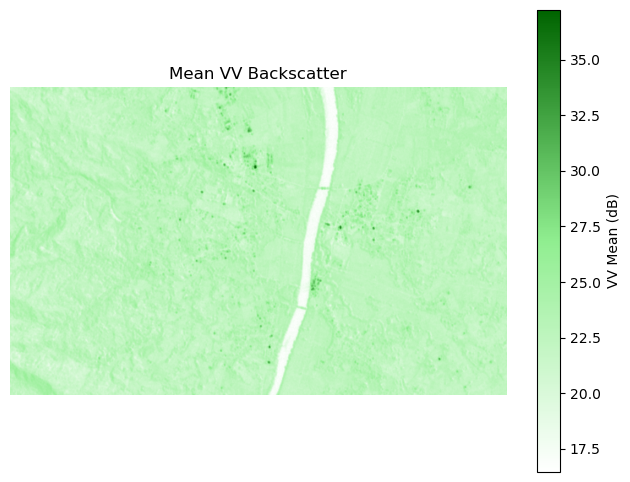

In [12]:
cmap = LinearSegmentedColormap.from_list(
    "water_land",
    ["white", "lightgreen", "darkgreen"]
)

plt.figure(figsize=(8,6))
plt.imshow(vv_mean, cmap=cmap)
plt.colorbar(label='VV Mean (dB)')
plt.title('Mean VV Backscatter')
plt.axis('off')
plt.show()

## Apply Water Mask
A water mask was applied to the Sentinel-1 VV backscatter image to isolate water bodies within the study area. The mask was generated using a backscatter threshold, where pixels representing open water were separated from surrounding land surfaces. Due to the smooth nature of water surfaces, radar signals are reflected away from the sensor, resulting in lower backscatter values compared to land.

The water mask was used to identify the river channel and other surface water features, allowing subsequent analyses, such as soil moisture assessment, to focus on land areas while preserving information on water extent.

In [13]:
#Apply mask
water_mask = vv_mean < 19


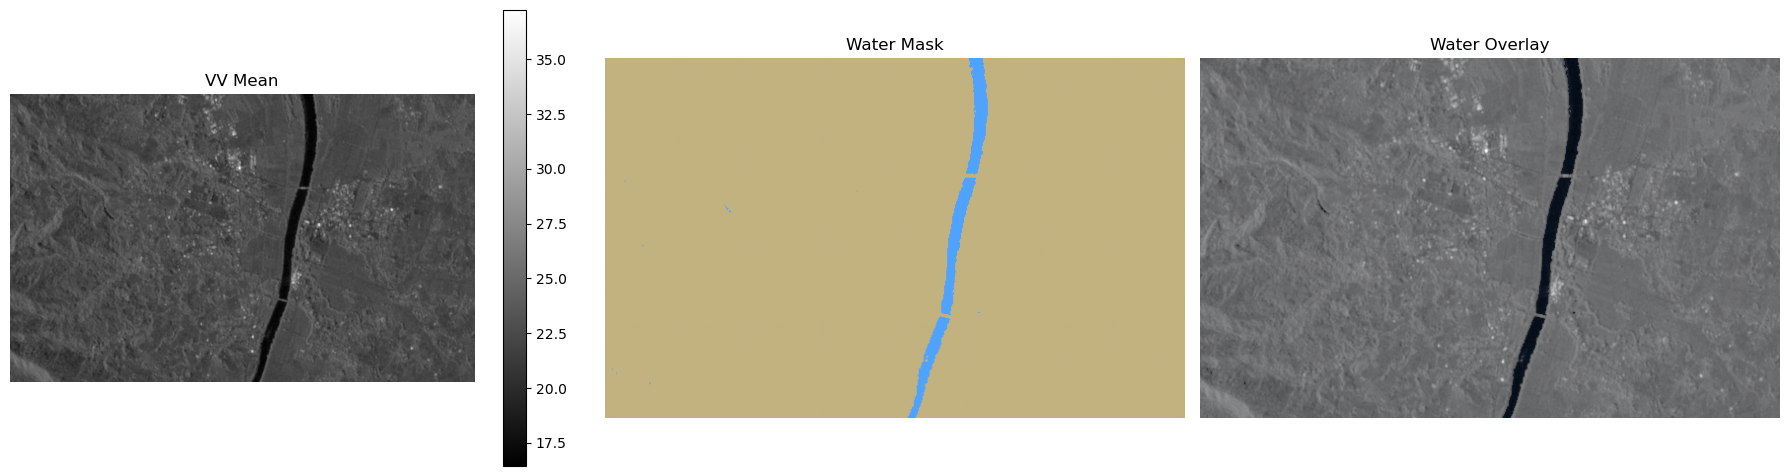

In [14]:
from matplotlib.colors import ListedColormap
import matplotlib.pyplot as plt

# Water mask colours
mask_cmap = ListedColormap([
    '#C2B280',  # land
    '#4FA3FF'         # water
])

fig, ax = plt.subplots(1, 3, figsize=(18, 6))

# Panel 1: Original VV mean
im = ax[0].imshow(vv_mean, cmap='gray')
ax[0].set_title('VV Mean')
ax[0].axis('off')
plt.colorbar(im, ax=ax[0], shrink=0.8)

# Panel 2: Water mask
ax[1].imshow(water_mask, cmap=mask_cmap)
ax[1].set_title('Water Mask')
ax[1].axis('off')

# Panel 3: VV mean with water overlay
ax[2].imshow(vv_mean, cmap='gray')
ax[2].imshow(water_mask, cmap='Blues', alpha=0.2)
ax[2].set_title('Water Overlay')
ax[2].axis('off')

plt.tight_layout()
plt.show()

In [15]:
print(float(vv_mean.min()))
print(float(vv_mean.max()))
print(float(vv_mean.mean()))

16.445064544677734
37.24750900268555
22.607383728027344


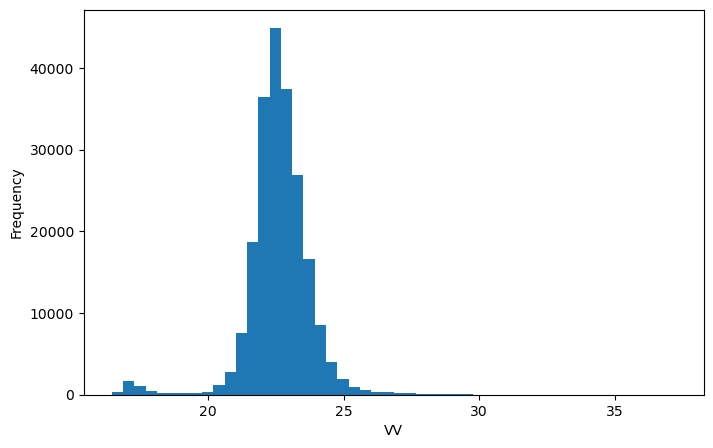

In [16]:
#Plot a histogram
plt.figure(figsize=(8,5))
plt.hist(vv_mean.values.flatten(), bins=50)
plt.xlabel("VV")
plt.ylabel("Frequency")
plt.show()

## Speckle Filtering
- Reduce some noise within the image
- Speckle filtering was applied to the Sentinel-1 SAR imagery to reduce the granular noise inherent in radar data while preserving important image features such as water boundaries and landscape patterns.
- Speckle is a common characteristic of SAR imagery caused by the coherent interaction of radar signals with surface targets, which can reduce image interpretability and affect subsequent analyses.

In [17]:
import numpy as np
from scipy.ndimage import uniform_filter

def lee_filter(img, size=5):
    """
    Lee speckle filter

    Parameters
    ----------
    img : numpy array
        Input image
    size : int
        Moving window size

    Returns
    -------
    filtered_img : numpy array
    """

    img_mean = uniform_filter(img, size)
    img_sqr_mean = uniform_filter(img**2, size)

    img_variance = img_sqr_mean - img_mean**2

    overall_variance = np.nanvar(img)

    weights = img_variance / (img_variance + overall_variance)

    filtered_img = img_mean + weights * (img - img_mean)

    return filtered_img

In [18]:
water_vv = vv_mean.where(water_mask)

lee_filtered = lee_filter(
    water_vv.fillna(0).values,
    size=5
)

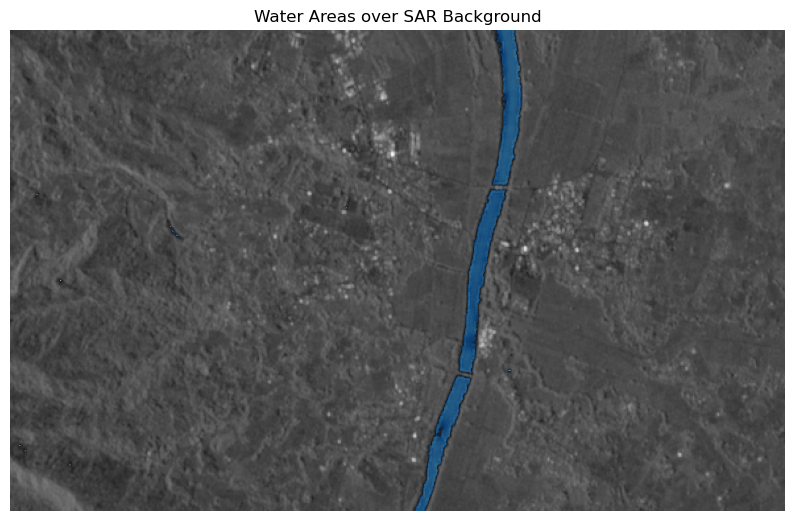

In [19]:
plt.figure(figsize=(10,10))

# Land
plt.imshow(vv_mean, cmap='gray')

# Water overlay
plt.imshow(
    np.where(np.isnan(water_vv), np.nan, lee_filtered),
    cmap='Blues',
    alpha=0.7
)

plt.title('Water Areas over SAR Background')
plt.axis('off')
plt.show()

## DETERMINE DRY  and WET DIFFERENCE CONDITION
To estimate soil moisture conditions, wet and dry reference backscatter values were derived from the Sentinel-1 VV backscatter distribution within the DEM-masked study area. These reference conditions represent the relative extremes of surface moisture and were used as inputs for calculating the Soil Moisture Index (SMI).

The 75th percentile of the VV backscatter distribution was selected as the **wet reference condition (VVwet)**, representing areas with relatively high moisture content, while the 25th percentile was selected as the **dry reference condition (VVdry)**, representing areas with relatively low moisture content. This percentile-based approach minimizes the influence of outliers and provides representative wet and dry conditions across the study area.
The derived reference values were then used to normalize Sentinel-1 VV backscatter values and calculate the Soil Moisture Index (SMI), enabling the identification and mapping of relative wet and dry areas within the floodplain.

**Purpose:**
- Establish representative wet and dry backscatter conditions.
- Provide reference values for SMI calculation.
- Differentiate areas with varying levels of soil moisture.

**Output:**
- Wet reference backscatter value (VVwet).
- Dry reference backscatter value (VVdry).
- Threshold values used for SMI estimation.

1. Dry Difference

2. Wet Difference

In [20]:
land_only = vv_mean.where(~water_mask)

In [21]:
valid_land = land_only.values[
    ~np.isnan(land_only.values)
]

p25 = np.percentile(valid_land, 25)
p75 = np.percentile(valid_land, 75)

wet = land_only < p25
moderate = (land_only >= p25) & (land_only <= p75)
dry = land_only > p75

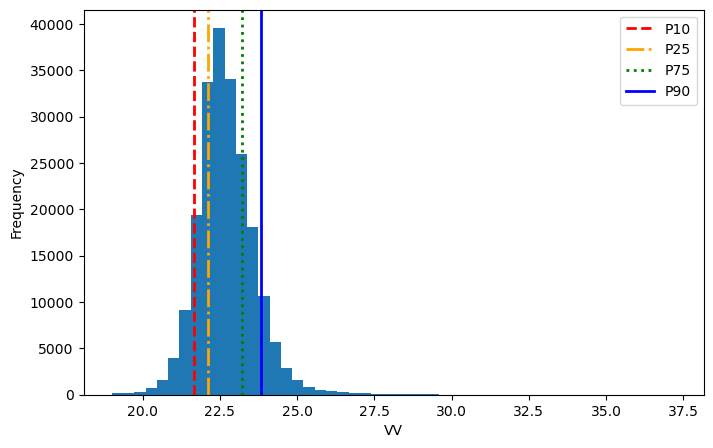

In [22]:
#Test
plt.figure(figsize=(8,5))
plt.hist(valid_land, bins=50)

plt.axvline(np.percentile(valid_land,10),
            color="red",
            linestyle="--",
            linewidth=2,
            label="P10")

plt.axvline(np.percentile(valid_land,25),
            color="orange",
            linestyle="-.",
            linewidth=2,
            label="P25")

plt.axvline(np.percentile(valid_land,75),
            color="green",
            linestyle=":",
            linewidth=2,
            label="P75")

plt.axvline(np.percentile(valid_land,90),
            color="blue",
            linestyle="-",
            linewidth=2,
            label="P90")

plt.xlabel("VV")
plt.ylabel("Frequency")
plt.legend()
plt.show()

In [23]:
print("P10 =", np.percentile(valid_land,10))
print("P25 =", np.percentile(valid_land,25))
print("P75 =", np.percentile(valid_land,75))
print("P90 =", np.percentile(valid_land,90))

P10 = 21.677233505249024
P25 = 22.12441062927246
P75 = 23.213895797729492
P90 = 23.818830490112305


In [24]:
#Test
p10 = np.percentile(valid_land, 10)
p25 = np.percentile(valid_land, 25)
p75 = np.percentile(valid_land, 75)
p90 = np.percentile(valid_land, 90)

very_dry = land_only < p10

dry = (land_only >= p10) & (land_only < p25)

normal = (land_only >= p25) & (land_only < p75)

wet = (land_only >= p75) & (land_only < p90)

very_wet = land_only >= p90

In [25]:
import numpy as np
import xarray as xr

# Mask out water
land_only = vv_mean.where(~water_mask)

# Extract valid land pixels
valid_land = land_only.values[~np.isnan(land_only.values)]

# Calculate percentiles
p10 = np.percentile(valid_land, 10)
p25 = np.percentile(valid_land, 25)
p75 = np.percentile(valid_land, 75)
p90 = np.percentile(valid_land, 90)

print(f"P10 = {p10:.3f}")
print(f"P25 = {p25:.3f}")
print(f"P75 = {p75:.3f}")
print(f"P90 = {p90:.3f}")

# Initialize classification raster
wetness_class = xr.full_like(land_only, np.nan)

# Classify
wetness_class = xr.where(land_only < p10, 1, wetness_class)

wetness_class = xr.where(
    (land_only >= p10) & (land_only < p25),
    2,
    wetness_class
)

wetness_class = xr.where(
    (land_only >= p25) & (land_only < p75),
    3,
    wetness_class
)

wetness_class = xr.where(
    (land_only >= p75) & (land_only < p90),
    4,
    wetness_class
)

wetness_class = xr.where(
    land_only >= p90,
    5,
    wetness_class
)

P10 = 21.677
P25 = 22.124
P75 = 23.214
P90 = 23.819


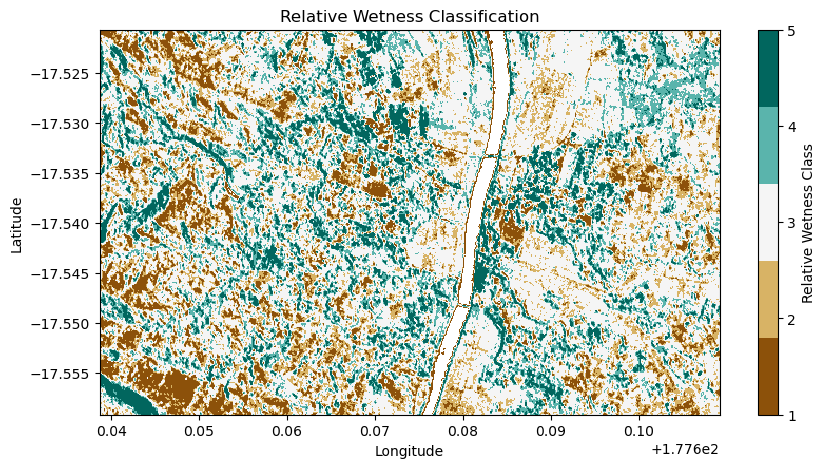

In [26]:
#Test
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

cmap = ListedColormap([
    "#8c510a",  # Very Dry
    "#d8b365",  # Dry
    "#f5f5f5",  # Normal
    "#5ab4ac",  # Wet
    "#01665e"   # Very Wet
])

plt.figure(figsize=(10, 5))

wetness_class.plot(
    cmap=cmap,
    vmin=1,
    vmax=5,
    add_colorbar=True,
    cbar_kwargs={
        "ticks": [1, 2, 3, 4, 5],
        "label": "Relative Wetness Class"
    }
)

plt.title("Relative Wetness Classification")
plt.xlabel("Longitude")
plt.ylabel("Latitude")

plt.show()

In [27]:
# --- CORRECTED LAND LOGIC ---
# High backscatter = Wet land
wet = land_only > p75

# Intermediate backscatter = Moderate land
moderate = (land_only >= p25) & (land_only <= p75)

# Low backscatter = Dry land
dry = land_only < p25

In [28]:
#Test
classification = np.full(vv_mean.shape, np.nan)

# Water
classification[water_mask] = 0

# Land classes
classification[very_dry] = 1
classification[dry]      = 2
classification[normal]   = 3
classification[wet]      = 4
classification[very_wet] = 5

In [29]:
classification = np.full(vv_mean.shape, np.nan)

classification[dry] = 3
classification[moderate] = 2
classification[wet] = 1

# Force river pixels to wet
classification[water_mask] = 1

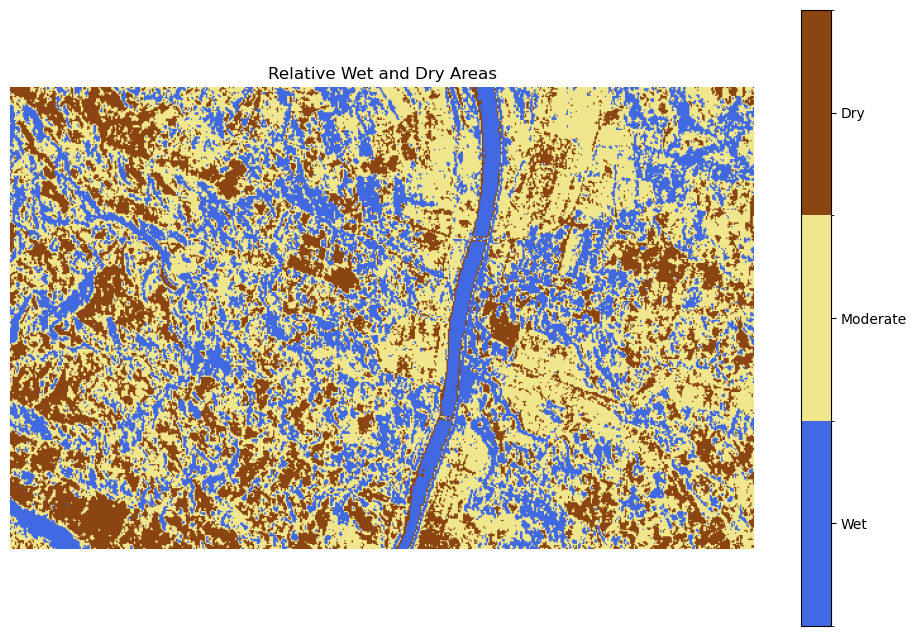

In [30]:
from matplotlib.colors import ListedColormap, BoundaryNorm

cmap = ListedColormap(["royalblue", "khaki", "saddlebrown"])

# Define discrete boundaries around classes 1, 2, and 3
bounds = [0.5, 1.5, 2.5, 3.5]
norm = BoundaryNorm(bounds, cmap.N)

plt.figure(figsize=(12, 8))
im = plt.imshow(classification, cmap=cmap, norm=norm)

# Set ticks at the center of each block
cbar = plt.colorbar(im, ticks=[1, 2, 3])
cbar.set_ticklabels(["Wet", "Moderate", "Dry"])

plt.title("Relative Wet and Dry Areas")
plt.axis("off")
plt.show()

## DEM
- Masking Elevation above 30- 40m
- Calculate the slope
- Calculate the aspect

Applying the DEM mask improved the representation of soil moisture conditions by restricting the analysis to the floodplain and adjacent low-elevation areas where hydrological processes are most relevant.

**Purpose:**
- Focus the analysis on low-lying flood-prone terrain.
- Exclude elevated areas unlikely to be affected by flooding.
- Improve the interpretation of soil moisture patterns within the floodplain.

In [31]:
from odc.stac import load
from pystac_client import Client

# Open Element84 STAC
e84_catalog = "https://earth-search.aws.element84.com/v1/"
e84_client = Client.open(e84_catalog)

# Search DEM tiles covering your study area
items = e84_client.search(
    collections=["cop-dem-glo-30"],
    bbox=list(ds.odc.geobox.geographic_extent.boundingbox)
).item_collection()

# Load DEM
elevation = load(
    items,
    measurements=["data"],
    geobox=ds.odc.geobox
).squeeze()

In [32]:
lowland_mask = elevation.data < 30   # or 40 m

lowland_vv = vv_mean.where(lowland_mask)

In [33]:
#Test
from matplotlib.colors import ListedColormap, BoundaryNorm
import matplotlib.pyplot as plt

# 0=Water, 1=Very Dry, 2=Dry, 3=Normal, 4=Wet, 5=Very Wet
cmap = ListedColormap([
    "royalblue",   # Water
    "#8c510a",     # Very Dry
    "#d8b365",     # Dry
    "#f7f7f7",     # Normal
    "#5ab4ac",     # Wet
    "#01665e"      # Very Wet
])

# Areas outside lowlands (<30 m) will be white
cmap.set_bad("white")

bounds = [-0.5, 0.5, 1.5, 2.5, 3.5, 4.5, 5.5]
norm = BoundaryNorm(bounds, cmap.N)

plt.figure(figsize=(12, 8))

im = plt.imshow(
    classification_lowland,
    cmap=cmap,
    norm=norm
)

cbar = plt.colorbar(im, ticks=[0, 1, 2, 3, 4, 5])

cbar.set_ticklabels([
    "Water",
    "Very Dry",
    "Dry",
    "Normal",
    "Wet",
    "Very Wet"
])

plt.title("Relative Wetness in Low-Lying Areas (<30 m)")
plt.axis("off")

plt.show()

NameError: name 'classification_lowland' is not defined

<Figure size 1200x800 with 0 Axes>

In [ ]:
from matplotlib.colors import ListedColormap, BoundaryNorm

# Define colors for values 1 (Wet), 2 (Moderate), 3 (Dry)
cmap = ListedColormap(["royalblue", "khaki", "saddlebrown"])

# Create discrete boundaries centered around 1, 2, and 3
bounds = [0.5, 1.5, 2.5, 3.5]
norm = BoundaryNorm(bounds, cmap.N)

# Set background (masked values/NaNs) to white
cmap.set_bad(color="white")

plt.figure(figsize=(12, 8))

# Display the masked classification array
im = plt.imshow(classification_lowland, cmap=cmap, norm=norm)

# Add colorbar
cbar = plt.colorbar(im, ticks=[1, 2, 3])
cbar.set_ticklabels(["Wet", "Moderate", "Dry"])

plt.title("Relative Wetness in Low-Lying Areas (<30 m)")
plt.axis("off")
plt.show()

In [ ]:
import numpy as np

# Create a copy of classification to avoid mutating the original
classification_lowland = classification.copy()

# Mask out areas where elevation >= 30m (set them to NaN or 0)
# Option A: If classification is a numpy array
classification_lowland[~lowland_mask.values] = np.nan

# Option B: If lowland_mask is already a numpy boolean array, just use:
# classification_lowland[~lowland_mask] = np.nan

## Calculate Soil Moisture Index
The Soil Moisture Index (SMI) was calculated to quantify the relative moisture conditions across the study area using Sentinel-1 VV backscatter data. 
Following DEM masking, only low-lying areas below 30 m elevation were included in the analysis to focus on flood-prone terrain.

## Loads the DEM and aligns it to the same grid as the soil moisture dataset (ds).


measurements=["data"]

Loads elevation values.

geobox=ds.odc.geobox

Ensures matching resolution and coordinate system.

.squeeze()

Removes unnecessary dimensions.

In [ ]:
# Extract land pixels by excluding areas identified as water
land_vv = vv_mean.where(~water_mask)

In [ ]:
#Test
# Lowland land pixels only
valid = vv_mean.values[
    (~np.isnan(vv_mean.values)) &
    (~water_mask) &
    (lowland_mask)
]

# Calculate percentile thresholds
p10 = np.percentile(valid, 10)
p25 = np.percentile(valid, 25)
p75 = np.percentile(valid, 75)
p90 = np.percentile(valid, 90)

print(f"P10 = {p10:.3f}")
print(f"P25 = {p25:.3f}")
print(f"P75 = {p75:.3f}")
print(f"P90 = {p90:.3f}")

In [ ]:
# Select valid backscatter values
# Remove NaN values and exclude very low values that may represent
# background noise or invalid pixels

valid = land_vv.values[
    (~np.isnan(land_vv.values)) &
    (land_vv.values > 1)
]

# Determine wet and dry reference backscatter values
# 25th percentile represents wetter conditions
# 75th percentile represents drier conditions
vv_wet = np.percentile(valid, 90)
vv_dry = np.percentile(valid, 10)

In [ ]:
# Calculate Soil Moisture Index (SMI)
# Higher values indicate wetter conditions
# Lower values indicate drier conditions
smi = (land_vv - vv_dry) / (vv_wet - vv_dry)

In [ ]:
# Constrain SMI values to the range 0–1
smi = smi.clip(min=0, max=1)

In [ ]:
# Display the Soil Moisture Index map
plt.figure(figsize=(12,8))

plt.imshow(
    smi,
    cmap="RdBu",
    vmin=0,
    vmax=1
)

cbar = plt.colorbar()
cbar.set_label("SMI")

plt.title("Soil Moisture Index")
plt.axis("off")

plt.show()

In [ ]:
# extract valid SMI values
smi_values = smi.values
valid_smi = smi_values[~np.isnan(smi_values)]

# summary statistics
print(f"Count   : {len(valid_smi):,}")
print(f"Minimum : {valid_smi.min():.3f}")
print(f"Maximum : {valid_smi.max():.3f}")
print(f"Mean    : {valid_smi.mean():.3f}")
print(f"Median  : {np.median(valid_smi):.3f}")
print(f"Std Dev : {valid_smi.std():.3f}")

# quartiles
print(f"10%     : {np.percentile(valid_smi, 10):.3f}")
print(f"50%     : {np.percentile(valid_smi, 50):.3f}")
print(f"90%     : {np.percentile(valid_smi, 90):.3f}")

In [ ]:
# Apply DEM mask
smi_masked = smi.where(lowland_mask)

In [ ]:
print(smi_masked)

In [ ]:
print("NaN pixels:", np.isnan(smi_masked).sum())

In [ ]:
print("Original valid pixels:",
      smi.notnull().sum().compute())

print("Masked valid pixels:",
      smi_masked.notnull().sum().compute())

### Soil Moisture Index (SMI) Map Interpretation

The Soil Moisture Index (SMI) map illustrates the spatial distribution of relative soil moisture conditions within the study area after applying a Digital Elevation Model (DEM) mask. Areas above the specified elevation threshold were excluded from the analysis to focus on low-lying terrain that is more susceptible to water accumulation and flooding.

The SMI was calculated using Sentinel-1 VV backscatter values according to:

\[
SMI = \frac{VV - VV_{dry}}{VV_{wet} - VV_{dry}}
\]

where:

- \(VV\) is the observed backscatter value,
- \(VV_{wet}\) represents the wet reference backscatter,
- \(VV_{dry}\) represents the dry reference backscatter.

The resulting SMI values range from 0 to 1:

- **SMI values close to 0** (dark purple) indicate relatively dry conditions.
- **SMI values close to 1** (yellow) indicate relatively wet conditions.
- **Intermediate values** (green to turquoise) represent moderate moisture conditions.

The map reveals substantial spatial variability in soil moisture across the floodplain. Areas with high SMI values are concentrated along low-lying zones and drainage pathways, indicating wetter soils with greater moisture retention. Conversely, areas with low SMI values correspond to drier surfaces with lower relative soil moisture.

The white areas visible in the map represent regions excluded from analysis through DEM masking or other preprocessing steps. These areas typically correspond to higher elevations that are less relevant to floodplain moisture assessment.

Overall, the SMI map highlights patterns of moisture distribution within the low-elevation landscape and demonstrates the utility of Sentinel-1 SAR data for identifying wet and dry conditions in support of flood monitoring and environmental assessment.

In [ ]:
plt.figure(figsize=(14,8))
smi_masked.plot(
    cmap="RdBu",
    vmin=0,
    vmax=1,
    cbar_kwargs={"label": "SMI"}
)
plt.title("SMI (Elevation ≤ 30 m)")
plt.show()
plt.show()

### Interpretation of the Raw Soil Moisture Index (SMI)

The Raw Soil Moisture Index (SMI) was calculated using the equation:

\[
SMI = \frac{VV - VV_{dry}}{VV_{wet} - VV_{dry}}
\]

where:

- \(VV\) is the observed Sentinel-1 VV backscatter value,
- \(VV_{wet}\) is the wet reference backscatter,
- \(VV_{dry}\) is the dry reference backscatter.

Unlike the final SMI product, the raw SMI values were not constrained to the theoretical range of 0 to 1. As a result, values less than 0 and greater than 1 are retained, allowing assessment of how the observed backscatter compares with the selected wet and dry reference conditions.

### Statistical Summary

The raw SMI results show:

- **Values less than 0:** 52,640 pixels
- **Values between 0 and 1:** 105,282 pixels
- **Values greater than 1:** 52,641 pixels

This indicates that approximately half of the observations fall outside the theoretical 0-1 range, while the remaining pixels are distributed between the wet and dry reference conditions.



In [ ]:
raw_smi = (land_vv - vv_dry) / (vv_wet - vv_dry)

raw_valid = raw_smi.values[~np.isnan(raw_smi.values)]

print("Less than 0:", np.sum(raw_valid < 0))
print("Greater than 1:", np.sum(raw_valid > 1))
print("Between 0 and 1:", np.sum((raw_valid >= 0) & (raw_valid <= 1)))

In [ ]:
plt.figure(figsize=(8,5))
plt.hist(raw_valid, bins=50)
plt.xlabel("Raw SMI")
plt.ylabel("Frequency")
plt.title("Raw Soil Moisture Index")
plt.show()

### Interpretation of SMI Classes

#### SMI < 0
Pixels with negative SMI values have backscatter values lower than the selected dry reference value. These pixels may represent:

- Very dry surfaces,
- Areas with sparse vegetation,
- Local surface roughness effects,
- Residual SAR noise and speckle.

A total of **52,640 pixels** fall into this category.

#### 0 ≤ SMI ≤ 1
Pixels within this range represent moisture conditions bounded by the selected wet and dry reference values. These pixels are considered to have realistic relative moisture conditions ranging from dry to wet.

A total of **105,282 pixels** fall within this range.

#### SMI > 1
Pixels with SMI values greater than 1 have backscatter responses exceeding the selected wet reference value. These may correspond to:

- Saturated soils,
- Waterlogged surfaces,
- Flood-prone areas,
- Areas immediately adjacent to river channels and drainage networks.

A total of **52,641 pixels** fall into this category.

### Interpretation of the Histogram

The histogram displays a strongly unimodal distribution with a peak centred near **SMI = 0.5 to 1.0**. Most pixels are concentrated around this range, indicating that a large proportion of the study area exhibits moderate to high moisture conditions.

The distribution exhibits:

- A pronounced peak around intermediate moisture conditions.
- A left-skewed tail extending towards negative values.
- A smaller right tail extending beyond SMI values of 2.

The long negative tail suggests that some locations are substantially drier than the selected dry reference, whereas the positive tail suggests that some locations are wetter than the selected wet reference.

### Key Findings

- The majority of pixels are concentrated around moderate moisture conditions.
- Approximately **50% of pixels fall within the expected 0-1 SMI range**.
- Nearly equal numbers of pixels fall below 0 and above 1, indicating that the selected wet and dry reference values may be relatively restrictive.
- The distribution suggests substantial spatial variability in soil moisture across the low-lying floodplain.
- Areas represented by high SMI values are likely associated with wetter soils and potential moisture accumulation

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

smi_valid = smi_masked.values[~np.isnan(smi_masked.values)]

# SMI classes
dry = np.sum(smi_valid < 0.3)
moderate = np.sum((smi_valid >= 0.3) & (smi_valid <= 0.7))
wet = np.sum(smi_valid > 0.7)

total = len(smi_valid)

dry_pct = 100 * dry / total
moderate_pct = 100 * moderate / total
wet_pct = 100 * wet / total

# Print results
print("Soil Moisture Classes")
print("--------------------")
print(f"Wet Area (>0.7): {wet_pct:.2f}%")
print(f"Moderate Area (0.3-0.7): {moderate_pct:.2f}%")
print(f"Dry Area (<0.3): {dry_pct:.2f}%")  # <-- Add this line

In [ ]:
#5 class
import numpy as np
import matplotlib.pyplot as plt

smi_valid = smi_masked.values[
    ~np.isnan(smi_masked.values)
]

# SMI classes
very_dry = np.sum(smi_valid < 0.20)

dry = np.sum(
    (smi_valid >= 0.20) &
    (smi_valid < 0.40)
)

normal = np.sum(
    (smi_valid >= 0.40) &
    (smi_valid < 0.60)
)

wet = np.sum(
    (smi_valid >= 0.60) &
    (smi_valid < 0.80)
)

very_wet = np.sum(smi_valid >= 0.80)

total = len(smi_valid)

# Percentages
very_dry_pct = 100 * very_dry / total
dry_pct = 100 * dry / total
normal_pct = 100 * normal / total
wet_pct = 100 * wet / total
very_wet_pct = 100 * very_wet / total

# Print results
print("Soil Moisture Classes")
print("--------------------")
print(f"Very Dry Area (<0.20): {very_dry_pct:.2f}%")
print(f"Dry Area (0.20-0.40): {dry_pct:.2f}%")
print(f"Normal Area (0.40-0.60): {normal_pct:.2f}%")
print(f"Wet Area (0.60-0.80): {wet_pct:.2f}%")
print(f"Very Wet Area (>0.80): {very_wet_pct:.2f}%")

In [ ]:
classes = ["Wet", "Moderate", "Dry"]
percentages = [wet_pct, moderate_pct, dry_pct]

colors = ["royalblue", "khaki", "saddlebrown"]

plt.figure(figsize=(8,5))

bars = plt.bar(classes, percentages, color=colors)

plt.ylabel("Percentage (%)")
plt.title("Soil Moisture Classification")

# Add percentage labels on bars
for bar, pct in zip(bars, percentages):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 1,
        f"{pct:.1f}%",
        ha="center",
        fontsize=10
    )

plt.ylim(0, max(percentages) + 10)

plt.show()

### Soil Moisture Classification Results

The bar chart summarizes the proportion of wet, moderate, and dry areas derived from the Soil Moisture Index (SMI) within the DEM-masked study area. The classification was based on the following thresholds:

- **Wet:** SMI > 0.7
- **Moderate:** 0.3 ≤ SMI ≤ 0.7
- **Dry:** SMI < 0.3

#### Results

- **Wet Areas:** 36.8%
- **Moderately Moist Areas:** 23.4%
- **Dry Areas:** 39.9%

#### Interpretation

The study area is predominantly characterized by **dry and wet conditions**, with relatively fewer areas exhibiting moderate moisture levels.

The **dry class (39.9%)** represents the largest proportion of the landscape, indicating that much of the floodplain and surrounding low-elevation land experienced relatively low soil moisture conditions during the Sentinel-1 acquisition period.

The **wet class (36.8%)** accounts for a substantial proportion of the study area, suggesting the presence of areas with elevated moisture content. These locations are likely associated with low-lying terrain, flood-prone zones, drainage pathways, and areas adjacent to river channels where water accumulation and soil saturation are more common.

The **moderate moisture class (23.4%)** occupies the smallest proportion of the study area. This indicates that soil moisture conditions tended to cluster toward either relatively wet or relatively dry states rather than intermediate conditions.

Overall, the results show a heterogeneous moisture environment, with approximately equal proportions of wet and dry areas. This variability reflects differences in topography, drainage characteristics, land cover, and proximity to surface water sources across the low-lying landscape. The findings demonstrate the ability of Sentinel-1 SAR-derived SMI to identify and quantify spatial patterns of soil moisture, supporting environmental monitoring and flood-related assessments.

In [ ]:
#Test
classes = ["Very Dry", "Dry", "Normal", "Wet", "Very Wet"]

percentages = [
    very_dry_pct,
    dry_pct,
    normal_pct,
    wet_pct,
    very_wet_pct
]

colors = [
    "#8c510a",
    "#d8b365",
    "#f7f7f7",
    "#5ab4ac",
    "#01665e"
]

plt.figure(figsize=(8,5))

bars = plt.bar(
    classes,
    percentages,
    color=colors,
    edgecolor="black"
)

plt.ylabel("Area (%)")
plt.title("Relative Soil Moisture Classes (<30 m Land Areas)")

# Add labels
for bar, pct in zip(bars, percentages):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 0.5,
        f"{pct:.1f}%",
        ha="center",
        fontsize=10
    )

plt.ylim(0, max(percentages) + 10)

plt.tight_layout()
plt.show()

### Interpretation

The relative soil moisture classification reveals considerable spatial variability in moisture conditions across low-lying land areas (<30 m elevation). The distribution of pixels among the five classes indicates that soil moisture conditions are highly heterogeneous, with substantial portions of the landscape exhibiting both relatively dry and relatively wet conditions.

The Very Wet class (35.0%) represents the largest proportion of the study area, indicating that more than one-third of the lowland landscape experienced relatively high soil moisture conditions during the Sentinel-1 observation period. These areas are likely associated with poorly drained terrain, floodplains, wetlands, low-lying depressions, and locations with prolonged water retention.

The Very Dry class (30.6%) forms the second largest proportion of the study area, suggesting that a significant extent of the landscape exhibited relatively low moisture conditions. Such areas may correspond to well-drained surfaces, elevated portions of the floodplain, or locations with limited water accumulation.

The Dry (12.3%), Normal (11.9%), and Wet (10.2%) classes collectively account for approximately one-third of the study area. The relatively small proportions of these intermediate classes indicate that soil moisture conditions tended to be concentrated toward the wetter and drier ends of the observed range rather than around average conditions.

Overall, the results suggest a landscape characterized by strong moisture contrasts, with approximately 65.6% of the study area classified as either Very Dry or Very Wet. This pattern reflects the influence of local topography, drainage characteristics, land cover, and hydrological processes that control the spatial distribution of soil moisture. The findings demonstrate the capacity of Sentinel-1 SAR-derived Soil Moisture Index (SMI) to identify areas of relative moisture surplus and deficit, providing valuable information for floodplain assessment, environmental monitoring, and land management applications.

Key Findings:
- Very Wet: 35.0%
- Very Dry: 30.6%
- Dry: 12.3%
- Normal: 11.9%
-
  Wet: 10.2%

The most notable result is that the landscape is dominated by the two extreme moisture classes (Very Wet and Very Dry), while intermediate moisture conditions occupy a comparatively smaller area. This suggests strong spatial variability in soil moisture across the low-lying portions of the study area.

In [ ]:
#Export as tiff

In [ ]:
import rioxarray

# Write CRS if needed
smi_masked = smi_masked.rio.write_crs("EPSG:4326")

# Export GeoTIFF
smi_masked.rio.to_raster("smi_dem_masked_2024.tif")